In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Positional Bias — Qwen2.5-VL-3B-Instruct across Kvasir-SEG, ISIC 2018, and LGG (50 images each)

Runs **Qwen2.5-VL-3B-Instruct** (`Qwen/Qwen2.5-VL-3B-Instruct`) zero-shot on 50 sampled images x 5
positional prompts (P0-P4) from `position_bias_research_plan.md` per dataset, and scores its answers
against the ground truth already computed in each dataset's `manifest_<name>.csv`.

**Scope of this run**
- Datasets: Kvasir-SEG (colon polyps), ISIC 2018 (skin lesions), LGG Segmentation (brain tumors) —
  50 images x 5 prompts = 250 rows each
- Model: Qwen2.5-VL-3B-Instruct (smaller/faster sibling of the 7B, same architecture and grounding
  behavior), zero-shot, no fine-tuning, loaded **once** and reused across all 3 datasets
- Qwen2.5-VL is a **chat model** (per the plan's Input column: image + free-text chat), not a
  dedicated detector like Grounding DINO/OWLv2 -- every row is a full `apply_chat_template` +
  `generate()` call, so this is much slower per row than OWLv2's single forward pass
- **Bbox tier**: the plan lists Qwen2.5-VL's output as "Bounding box, point, or JSON coordinates" --
  we ask it (via a fixed, format-only instruction appended after `prompt_text`, identical across all
  5 prompts) to answer with a `{"bbox_2d": [x_min, y_min, x_max, y_max]}` JSON object, coordinates
  normalized 0-1000, then convert to this image's own pixel space. This sidesteps having to know
  Qwen's internal (possibly resized) vision-token resolution.
- Same defensive rule as the other notebooks: a box spanning (almost) the whole image, or a response
  that fails to parse, is treated as "no detection" (NaN), not a real position
- **Memory note**: Qwen2.5-VL-3B in bf16 is only ~6 GB of weights, so it fits comfortably on a 16 GB
  T4 without quantization; `USE_4BIT` is still available in the model-loading cell if you want an
  even smaller footprint.

**What this notebook produces, per dataset `<name>` in `{kvasir, isic, lgg}`**
- `results_<name>_qwen25vl/<name>_qwen25vl_results.csv` — the manifest plus new prediction/scoring
  columns appended after `prompt_text`
- `results_<name>_qwen25vl/visualizations/<sample_id>.png` — one figure per image, all 5 prompts side
  by side, showing ground truth (red) vs. Qwen2.5-VL's parsed box (blue)
- `results_<name>_qwen25vl/<name>_qwen25vl_summary_by_prompt.csv` — aggregated wrong-side rate /
  distance by prompt
- Inline plots in this notebook for a handful of examples plus the summary charts, per dataset

## How to run this in Google Colab

1. Upload the entire `run_colab/` folder (this notebook + `data/kvasir/`, `data/isic/`, `data/lgg/`)
   into your Colab session, or mount Google Drive and place it there (this notebook mounts Drive at
   `/content/drive` and expects the folder at `/content/drive/MyDrive/run_colab`).
2. `Runtime > Change runtime type > T4 GPU` is sufficient -- the 3B model fits comfortably without
   quantization.
3. Run all cells top to bottom. **No Hugging Face token is needed** — `Qwen/Qwen2.5-VL-3B-Instruct` is
   a public, non-gated model.
4. Inference is still slower than the OWLv2/Moondream2 notebooks (this is a chat model doing full
   text generation per row, not a single forward pass), but noticeably faster than the 7B variant.
5. If you see `KeyError: 'qwen2_5_vl'`, your `transformers` install predates Qwen2.5-VL support --
   rerun the install cell, or install straight from source per the model card:
   `pip install git+https://github.com/huggingface/transformers accelerate`.
6. Just run every cell top to bottom, in order, on a fresh runtime -- there is no manual setup step
   and nothing needs to have been run before; the final loop cell processes Kvasir-SEG, ISIC 2018, and
   LGG one after another using the functions defined earlier in the notebook.

In [3]:
%pip install -q "transformers==4.56.1" "accelerate==1.10.1" "qwen-vl-utils==0.0.8" "bitsandbytes==0.47.0" pillow pandas matplotlib tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 117.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 MB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 125.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 32.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [4]:
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    ROOT = Path("/content/drive/MyDrive/run_colab")
    if not ROOT.exists():
        raise FileNotFoundError(
            "Upload the whole 'run_colab' folder into /content (e.g. drag it into the Colab file "
            "browser on the left, or mount Drive and copy it there) before running this cell."
        )
else:
    ROOT = Path.cwd()
    if ROOT.name != "run_colab":
        candidate = ROOT / "run_colab"
        ROOT = candidate if candidate.exists() else ROOT

print(f"ROOT = {ROOT}")


def get_dataset_paths(dataset_name, results_folder):
    """Return (data_dir, out_dir, vis_dir) for one dataset, creating the output dirs."""
    data_dir = ROOT / "data" / dataset_name
    out_dir = ROOT / results_folder
    vis_dir = out_dir / "visualizations"
    out_dir.mkdir(parents=True, exist_ok=True)
    vis_dir.mkdir(parents=True, exist_ok=True)
    return data_dir, out_dir, vis_dir

ROOT = /content/drive/MyDrive/run_colab


In [5]:
import pandas as pd


def load_manifest(dataset_name, data_dir):
    manifest = pd.read_csv(data_dir / f"manifest_{dataset_name}.csv")
    assert len(manifest) == 250, f"{dataset_name}: expected 250 rows (50 images x 5 prompts), got {len(manifest)}"
    assert manifest["sample_id"].nunique() == 50, f"{dataset_name}: expected 50 unique images"
    print(f"[ok] {dataset_name}: loaded manifest with {len(manifest)} rows, {manifest['sample_id'].nunique()} images")
    return manifest

In [6]:
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("[warn] No GPU detected. Qwen2.5-VL-3B will be slow on CPU. In Colab: "
          "Runtime > Change runtime type > GPU.")

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"
USE_4BIT = False  # flip to True if you hit a CUDA out-of-memory error on a T4

if USE_4BIT and DEVICE == "cuda":
    from transformers import BitsAndBytesConfig
    quant_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.bfloat16)
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_NAME, quantization_config=quant_config, device_map="auto"
    )
else:
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_NAME,
        torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
        device_map="auto",
    )
model.eval()

# Fixed visual-token budget: 64 * 28 * 28 = ~50k pixels (~224x224).
# This keeps encoding fast and consistent across all images.
PIXEL_BUDGET = 64 * 28 * 28

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=PIXEL_BUDGET,
    max_pixels=PIXEL_BUDGET
)

print(f"[ok] loaded {MODEL_NAME} on {DEVICE} (4-bit={USE_4BIT}, pixel_budget={PIXEL_BUDGET})")

`torch_dtype` is deprecated! Use `dtype` instead!
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

chat_template.json: 0.00B [00:00, ?B/s]

[ok] loaded Qwen/Qwen2.5-VL-3B-Instruct on cuda (4-bit=False, pixel_budget=50176)


## Run inference

For each of the 250 (image, prompt) rows, we build a single-turn chat message (image + `prompt_text`)
exactly as documented on the model card, then append one **fixed, format-only instruction** (identical
across all 5 prompts, so it never becomes a second confounding variable alongside the P0-P4 positional
wording) asking for a `{"bbox_2d": [x_min, y_min, x_max, y_max]}` JSON object with coordinates
normalized 0-1000. We parse that JSON out of the generated text and rescale it to this image's own
pixel dimensions, so everything downstream matches the manifest's pixel-space ground truth
(`gt_centroid_x/y`, `gt_bbox_*`). Responses that don't parse are recorded as no-detection (NaN).

In [7]:
import json
import re

import numpy as np
from PIL import Image
from qwen_vl_utils import process_vision_info
from tqdm.auto import tqdm

GROUNDING_SUFFIX = (
    ' Respond with only a JSON object in the form {"bbox_2d": [x_min, y_min, x_max, y_max]}, with '
    "each coordinate normalized to an integer between 0 and 1000 relative to the image's width and "
    "height. Do not include any other text."
)


def build_qwen_messages(image, text):
    return [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": text + GROUNDING_SUFFIX},
        ],
    }]


def parse_qwen_bbox(output_text, width, height):
    """Parse a {"bbox_2d": [x1, y1, x2, y2]} (0-1000 normalized) JSON blob out of raw model text."""
    match = re.search(r"\{.*?\}", output_text, re.DOTALL)
    if not match:
        return None
    try:
        obj = json.loads(match.group(0))
        x1, y1, x2, y2 = obj["bbox_2d"]
    except Exception:
        return None
    return (x1 / 1000 * width, y1 / 1000 * height, x2 / 1000 * width, y2 / 1000 * height)


def run_qwen_detect(model, processor, device, image, text, max_new_tokens=128):
    """Return ((xmin, ymin, xmax, ymax) in pixels, or None, raw generated text)."""
    messages = build_qwen_messages(image, text)
    chat_text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[chat_text], images=image_inputs, videos=video_inputs, padding=True, return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        generated_ids = model.generate(**inputs, max_new_tokens=max_new_tokens)
    trimmed = [out[len(inp):] for inp, out in zip(inputs.input_ids, generated_ids)]
    output_text = processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]

    w, h = image.size
    box = parse_qwen_bbox(output_text, w, h)
    return box, output_text


def run_qwen_inference(model, processor, device, manifest_df, data_dir, desc="Qwen2.5-VL inference"):
    """Call Qwen2.5-VL for every row; returns a new df with qwen_xmin/ymin/xmax/ymax/raw_text columns."""
    df = manifest_df.copy()
    xmin_list, ymin_list, xmax_list, ymax_list, raw_list = [], [], [], [], []

    for _, row in tqdm(df.iterrows(), total=len(df), desc=desc):
        image = Image.open(data_dir / row["image_path"]).convert("RGB")

        try:
            box, raw_text = run_qwen_detect(model, processor, device, image, row["prompt_text"])
        except Exception as e:  # keep the run alive if one row errors out
            box, raw_text = None, f"[error] {e}"

        if box is not None:
            xmin_list.append(box[0]); ymin_list.append(box[1])
            xmax_list.append(box[2]); ymax_list.append(box[3])
        else:
            xmin_list.append(np.nan); ymin_list.append(np.nan)
            xmax_list.append(np.nan); ymax_list.append(np.nan)
        raw_list.append(raw_text)

    df["qwen_xmin"] = xmin_list
    df["qwen_ymin"] = ymin_list
    df["qwen_xmax"] = xmax_list
    df["qwen_ymax"] = ymax_list
    df["qwen_raw_text"] = raw_list

    print(f"[ok] ran inference on {len(df)} rows ({df['qwen_xmin'].isna().sum()} rows failed to parse a box)")
    return df

## Score predictions against ground truth

Adds, per row: predicted side (left/right, upper/lower), whether that matches the *prompted* direction
(RQ1/RQ3), whether the prompted direction actually matched this image's true ground-truth side (needed
to split rows for RQ2 vs RQ3), IoU of the Qwen2.5-VL box against `gt_bbox_*`, normalized distance to
`gt_centroid_x/y`, and the shift from this same image's own P0 answer (RQ1's "did it move at all?").

In [8]:
from PIL import Image as PILImage


def side_lr(x, width):
    return "left" if x < width / 2 else "right"


def side_ud(y, height):
    return "upper" if y < height / 2 else "lower"


PROMPT_AXIS = {
    "P0": (None, None),
    "P1": ("lr", "left"),
    "P2": ("lr", "right"),
    "P3": ("ud", "upper"),
    "P4": ("ud", "lower"),
}


def correct_side(row, side_lr_col, side_ud_col):
    # Returns 1.0/0.0 (not bool) and NaN (not None) so the column stays numeric for mean(numeric_only=True).
    if row["prompted_axis"] == "lr" and row[side_lr_col] is not None:
        return float(row[side_lr_col] == row["prompted_direction"])
    if row["prompted_axis"] == "ud" and row[side_ud_col] is not None:
        return float(row[side_ud_col] == row["prompted_direction"])
    return np.nan  # P0 has no prompted direction to compare against


def prompt_matches_gt(row):
    """Model-independent: does the prompted direction match this image's real ground truth side?"""
    if row["prompted_axis"] == "lr":
        return row["prompted_direction"] == row["gt_side_lr"]
    if row["prompted_axis"] == "ud":
        return row["prompted_direction"] == row["gt_side_ud"]
    return None


def iou(row):
    if pd.isna(row["qwen_xmin"]):
        return np.nan
    xa1, ya1, xa2, ya2 = row["qwen_xmin"], row["qwen_ymin"], row["qwen_xmax"], row["qwen_ymax"]
    xb1, yb1, xb2, yb2 = row["gt_bbox_xmin"], row["gt_bbox_ymin"], row["gt_bbox_xmax"], row["gt_bbox_ymax"]
    ix1, iy1 = max(xa1, xb1), max(ya1, yb1)
    ix2, iy2 = min(xa2, xb2), min(ya2, yb2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, xa2 - xa1) * max(0, ya2 - ya1)
    area_b = max(0, xb2 - xb1) * max(0, yb2 - yb1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else np.nan


def norm_dist(px, py, row):
    if pd.isna(px):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return np.hypot(px - row["gt_centroid_x"], py - row["gt_centroid_y"]) / diag


def no_shift(row, shift_col):
    """1.0 if the answer moved less than 5% of the image diagonal from its own P0 answer, else 0.0, NaN if not applicable."""
    if row["prompt_id"] == "P0" or pd.isna(row[shift_col]):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return float(row[shift_col] < 0.05 * diag)


def score_predictions(df, data_dir):
    """Add every derived scoring column: side labels, correct-side, IoU, normalized distance, shift-from-P0."""
    df = df.copy()

    sizes = {p: PILImage.open(data_dir / p).size for p in df["image_path"].unique()}
    df["img_width"] = df["image_path"].map(lambda p: sizes[p][0])
    df["img_height"] = df["image_path"].map(lambda p: sizes[p][1])

    # Same defensive rule as the other notebooks: a box spanning (almost) the whole image conveys no
    # real left/right or upper/lower signal (its center sits exactly at width/2, height/2), so treat
    # it as no detection (NaN) rather than letting the tie-break silently call it "right"/"lower".
    box_area = (df["qwen_xmax"] - df["qwen_xmin"]) * (df["qwen_ymax"] - df["qwen_ymin"])
    img_area = df["img_width"] * df["img_height"]
    degenerate = box_area >= 0.9 * img_area
    df["qwen_is_degenerate"] = degenerate
    df.loc[degenerate, ["qwen_xmin", "qwen_ymin", "qwen_xmax", "qwen_ymax"]] = np.nan
    print(f"[warn] {int(degenerate.sum())} / {len(df)} rows had a near-full-image Qwen2.5-VL box -> treated as no-detection")

    df["qwen_cx"] = (df["qwen_xmin"] + df["qwen_xmax"]) / 2
    df["qwen_cy"] = (df["qwen_ymin"] + df["qwen_ymax"]) / 2

    df["qwen_side_lr"] = df.apply(lambda r: side_lr(r["qwen_cx"], r["img_width"]) if pd.notna(r["qwen_cx"]) else None, axis=1)
    df["qwen_side_ud"] = df.apply(lambda r: side_ud(r["qwen_cy"], r["img_height"]) if pd.notna(r["qwen_cy"]) else None, axis=1)

    df["prompted_axis"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][0])
    df["prompted_direction"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][1])

    df["qwen_correct_side"] = df.apply(lambda r: correct_side(r, "qwen_side_lr", "qwen_side_ud"), axis=1)
    df["prompt_matches_gt"] = df.apply(prompt_matches_gt, axis=1)

    df["qwen_iou"] = df.apply(iou, axis=1)
    df["qwen_dist_norm"] = df.apply(lambda r: norm_dist(r["qwen_cx"], r["qwen_cy"], r), axis=1)

    p0_lookup = df[df["prompt_id"] == "P0"].set_index("sample_id")

    def shift_from_p0(row, x_col, y_col):
        if row["sample_id"] not in p0_lookup.index or pd.isna(row[x_col]):
            return np.nan
        p0x, p0y = p0_lookup.loc[row["sample_id"], x_col], p0_lookup.loc[row["sample_id"], y_col]
        if pd.isna(p0x):
            return np.nan
        return np.hypot(row[x_col] - p0x, row[y_col] - p0y)

    df["qwen_shift_from_p0"] = df.apply(lambda r: shift_from_p0(r, "qwen_cx", "qwen_cy"), axis=1)
    df["qwen_no_shift"] = df.apply(lambda r: no_shift(r, "qwen_shift_from_p0"), axis=1)

    print("[ok] derived scoring columns computed")
    return df

In [9]:
def save_results(df, out_dir, dataset_name):
    results_csv = out_dir / f"{dataset_name}_qwen25vl_results.csv"
    df.to_csv(results_csv, index=False)
    print(f"[ok] wrote {len(df)} rows x {len(df.columns)} columns -> {results_csv}")
    return results_csv

## Visualize: ground truth vs. Qwen2.5-VL's predictions

One figure per image, 5 panels (P0-P4): red = ground truth (box + centroid), blue = Qwen2.5-VL's
parsed box. Yellow lines mark the image's true midline/midheight, same convention as
`scripts/visualize_ground_truth.py`. All 50 are saved to disk; the first 2 are also shown inline here.

In [10]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

PROMPT_LABELS = {"P0": "P0 (neutral)", "P1": "P1 (left)", "P2": "P2 (right)", "P3": "P3 (upper)", "P4": "P4 (lower)"}


def plot_sample(df, data_dir, vis_dir, sample_id, save=True, show=False):
    rows = df[df["sample_id"] == sample_id].set_index("prompt_id")
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, prompt_id in zip(axes, ["P0", "P1", "P2", "P3", "P4"]):
        row = rows.loc[prompt_id]
        img = Image.open(data_dir / row["image_path"]).convert("RGB")
        ax.imshow(img)
        w, h = img.size

        gt_box = patches.Rectangle(
            (row["gt_bbox_xmin"], row["gt_bbox_ymin"]),
            row["gt_bbox_xmax"] - row["gt_bbox_xmin"],
            row["gt_bbox_ymax"] - row["gt_bbox_ymin"],
            linewidth=2, edgecolor="red", facecolor="none",
        )
        ax.add_patch(gt_box)
        ax.plot(row["gt_centroid_x"], row["gt_centroid_y"], "r+", markersize=12, markeredgewidth=2)

        if pd.notna(row["qwen_xmin"]):
            pred_box = patches.Rectangle(
                (row["qwen_xmin"], row["qwen_ymin"]),
                row["qwen_xmax"] - row["qwen_xmin"],
                row["qwen_ymax"] - row["qwen_ymin"],
                linewidth=2, edgecolor="dodgerblue", facecolor="none",
            )
            ax.add_patch(pred_box)

        ax.axvline(w / 2, color="yellow", linewidth=1)
        ax.axhline(h / 2, color="yellow", linewidth=1)
        ax.set_title(PROMPT_LABELS[prompt_id], fontsize=10)
        ax.axis("off")

    fig.suptitle(f"{sample_id}  |  ground truth: {rows.loc['P0', 'gt_side_lr']}/{rows.loc['P0', 'gt_side_ud']}  "
                 f"(red = ground truth, blue = Qwen2.5-VL prediction)")
    fig.tight_layout()
    if save:
        fig.savefig(vis_dir / f"{sample_id}.png", dpi=110)
    if show:
        plt.show()
    else:
        plt.close(fig)


def render_visualizations(df, data_dir, vis_dir, dataset_name, show_first=2):
    sample_ids = df["sample_id"].unique()
    for i, sid in enumerate(tqdm(sample_ids, desc=f"Rendering {dataset_name} visualizations")):
        plot_sample(df, data_dir, vis_dir, sid, save=True, show=(i < show_first))
    print(f"[ok] saved {len(sample_ids)} comparison plots -> {vis_dir}")

## Aggregate results (RQ1-RQ3)

- **RQ1** (does it shift when prompted?): `qwen_no_shift` — lower is better prompt-following.
- **RQ2** (consistent with GT when the prompt already matches it?): filter to `prompt_matches_gt == True`.
- **RQ3** (does it follow the prompt even when the prompt is wrong?): filter to `prompt_matches_gt == False`
  — a high `correct_side` rate here means the model privileges the text over the pixels.

In [11]:
def aggregate_and_report(df, out_dir, dataset_name):
    summary_cols = ["qwen_correct_side", "qwen_no_shift", "qwen_iou", "qwen_dist_norm"]
    by_prompt = df[df["prompt_id"] != "P0"].groupby("prompt_id")[summary_cols].mean(numeric_only=True)
    print(by_prompt)

    fig, ax = plt.subplots(figsize=(7, 4))
    by_prompt[["qwen_correct_side"]].plot(kind="bar", ax=ax, legend=False)
    ax.set_ylabel("share of rows matching the PROMPTED direction")
    ax.set_title(f"Prompt-following rate by prompt (Qwen2.5-VL, {dataset_name}, n=50 images)")
    ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(7, 4))
    by_prompt[["qwen_dist_norm"]].plot(kind="bar", ax=ax2, legend=False)
    ax2.set_ylabel("mean normalized distance to ground-truth centroid")
    ax2.set_title(f"Localization error by prompt ({dataset_name})")
    plt.tight_layout()
    plt.show()

    summary_csv = out_dir / f"{dataset_name}_qwen25vl_summary_by_prompt.csv"
    by_prompt.to_csv(summary_csv)
    print(f"[ok] wrote summary -> {summary_csv}")
    return by_prompt

In [12]:
def report_rq2_rq3(df, dataset_name):
    rq2 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == True)]
    print(f"RQ2 ({dataset_name}) -- prompt already matches ground truth (does wording alone still cause disagreement?):")
    print(rq2.groupby("prompt_id")[["qwen_correct_side", "qwen_dist_norm"]].mean(numeric_only=True))

    rq3 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == False)]
    print(f"\nRQ3 ({dataset_name}) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):")
    print(rq3.groupby("prompt_id")[["qwen_correct_side", "qwen_dist_norm"]].mean(numeric_only=True))

## Run all 3 datasets: Kvasir-SEG, ISIC 2018, LGG Segmentation

This section runs the exact same pipeline -- reusing the already-loaded `model`/`processor` and the
functions defined above -- on all 3 datasets, one after another, so every result/plot is produced by
identical code. Nothing needs to exist beforehand: this cell creates `results_kvasir_qwen25vl/`,
`results_isic_qwen25vl/`, and `results_lgg_qwen25vl/` (and their `visualizations/` subfolders) from
scratch.


Processing dataset: kvasir
[ok] kvasir: loaded manifest with 250 rows, 50 images


Qwen2.5-VL inference (kvasir):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows (1 rows failed to parse a box)
[warn] 1 / 250 rows had a near-full-image Qwen2.5-VL box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 35 columns -> /content/drive/MyDrive/run_colab/results_kvasir_qwen25vl/kvasir_qwen25vl_results.csv


Rendering kvasir visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

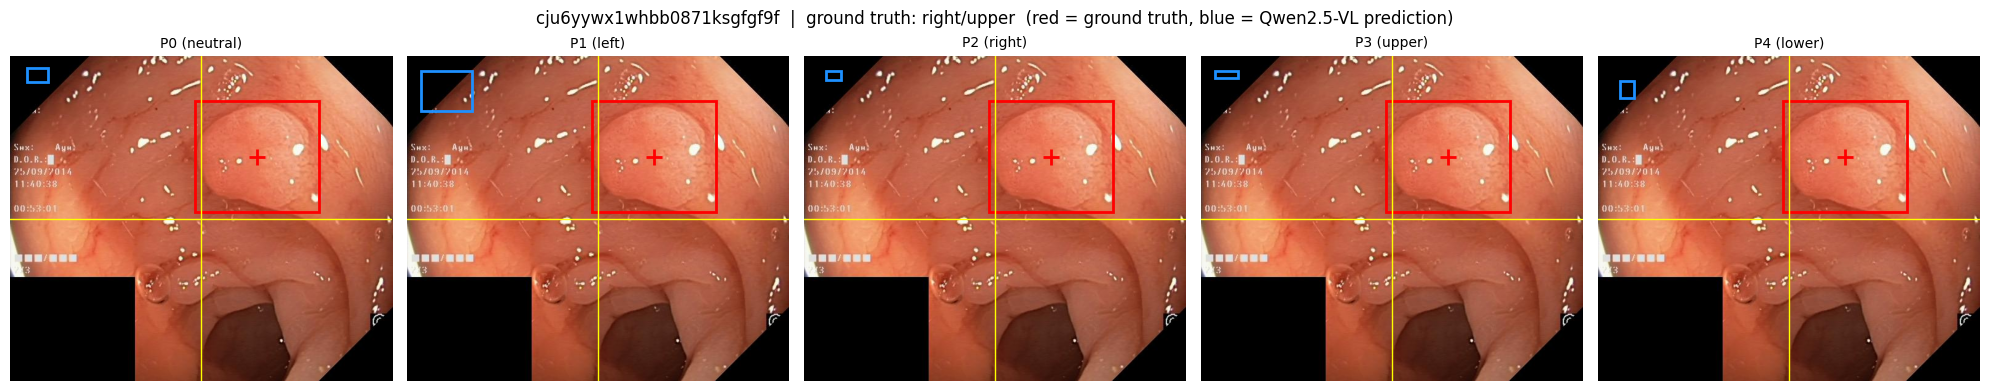

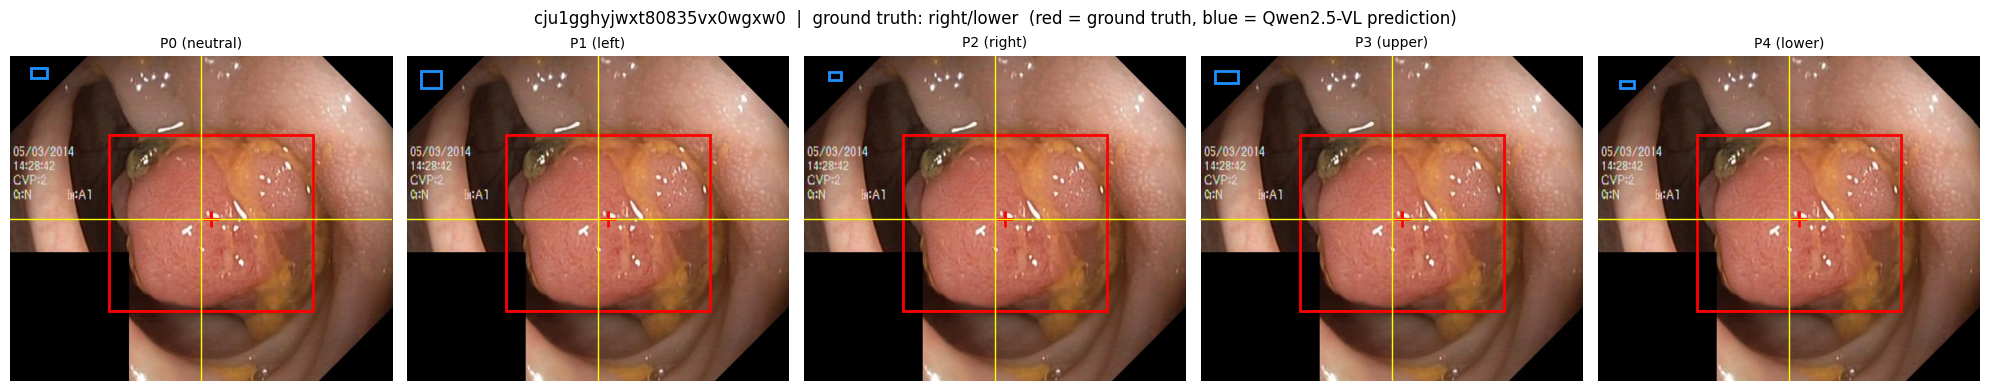

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_kvasir_qwen25vl/visualizations
           qwen_correct_side  qwen_no_shift  qwen_iou  qwen_dist_norm
prompt_id                                                            
P1                      1.00       0.833333  0.006256        0.450317
P2                      0.04       0.854167  0.001613        0.446891
P3                      1.00       0.895833  0.001127        0.470853
P4                      0.00       0.770833  0.001788        0.438201


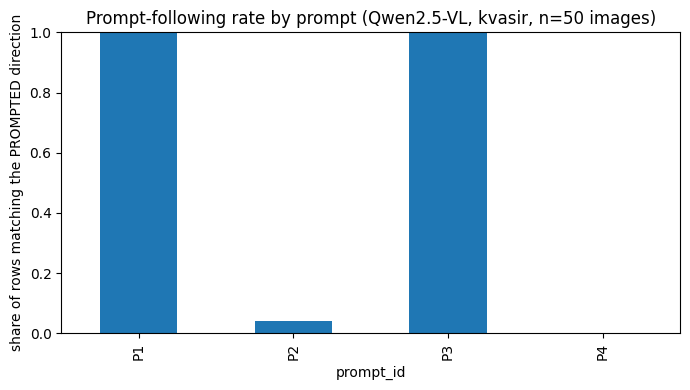

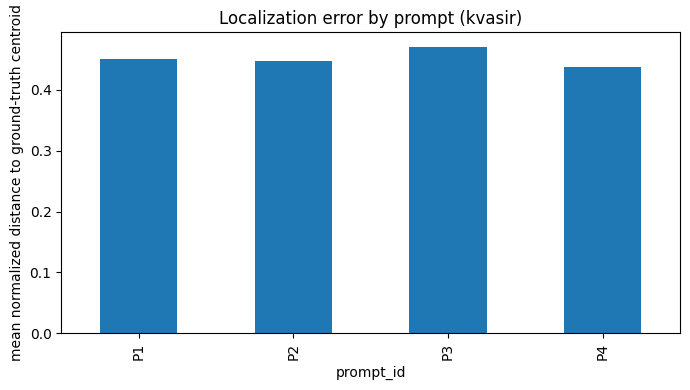

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_kvasir_qwen25vl/kvasir_qwen25vl_summary_by_prompt.csv
RQ2 (kvasir) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           qwen_correct_side  qwen_dist_norm
prompt_id                                   
P1                  1.000000        0.378128
P2                  0.057143        0.471255
P3                  1.000000        0.435958
P4                  0.000000        0.480511

RQ3 (kvasir) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           qwen_correct_side  qwen_dist_norm
prompt_id                                   
P1                       1.0        0.481255
P2                       0.0        0.390042
P3                       1.0        0.508656
P4                       0.0        0.399146

Processing dataset: isic
[ok] isic: loaded manifest with 250 rows, 50 images


Qwen2.5-VL inference (isic):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows (0 rows failed to parse a box)
[warn] 19 / 250 rows had a near-full-image Qwen2.5-VL box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 35 columns -> /content/drive/MyDrive/run_colab/results_isic_qwen25vl/isic_qwen25vl_results.csv


Rendering isic visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

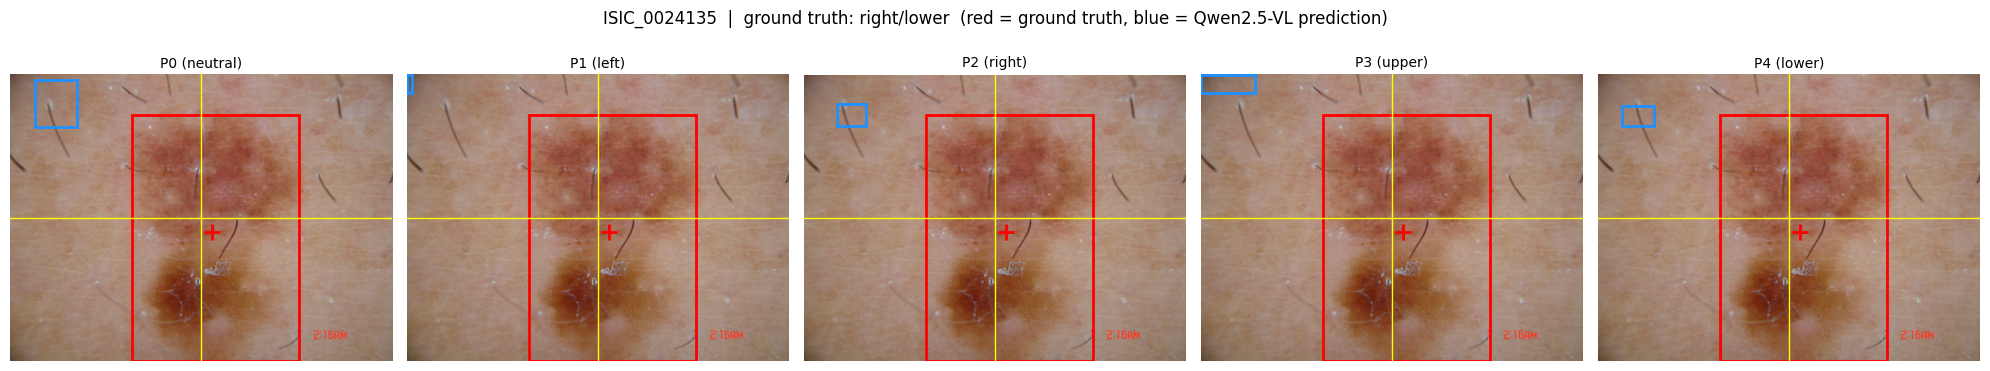

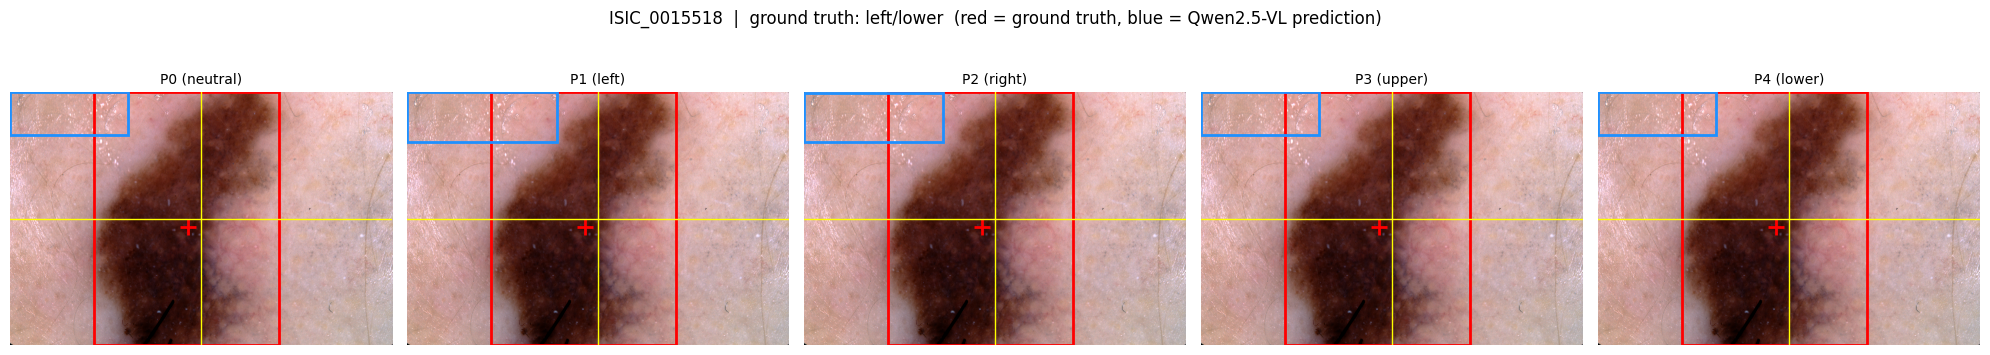

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_isic_qwen25vl/visualizations
           qwen_correct_side  qwen_no_shift  qwen_iou  qwen_dist_norm
prompt_id                                                            
P1                  0.936170       0.666667  0.016307        0.376925
P2                  0.020408       0.869565  0.015343        0.368707
P3                  1.000000       0.880952  0.010183        0.395557
P4                  0.000000       0.772727  0.009151        0.373890


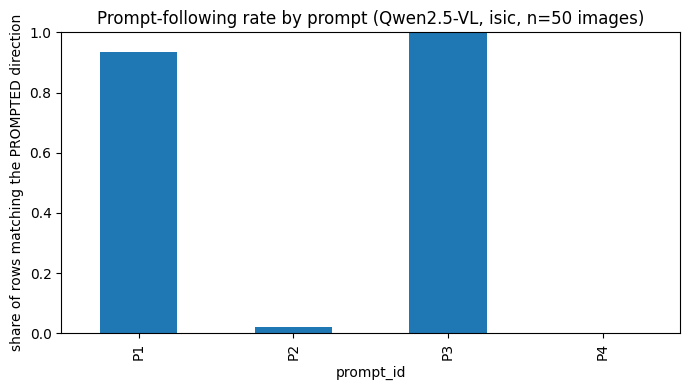

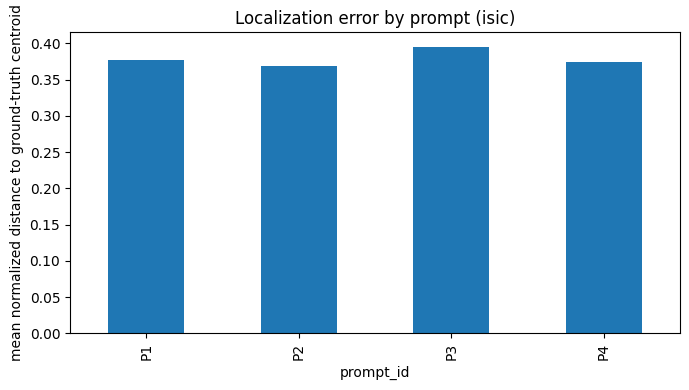

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_isic_qwen25vl/isic_qwen25vl_summary_by_prompt.csv
RQ2 (isic) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           qwen_correct_side  qwen_dist_norm
prompt_id                                   
P1                  0.916667        0.350864
P2                  0.040000        0.384077
P3                  1.000000        0.380460
P4                  0.000000        0.375392

RQ3 (isic) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           qwen_correct_side  qwen_dist_norm
prompt_id                                   
P1                  0.956522        0.404120
P2                  0.000000        0.352697
P3                  1.000000        0.411373
P4                  0.000000        0.372454

Processing dataset: lgg
[ok] lgg: loaded manifest with 250 rows, 50 images


Qwen2.5-VL inference (lgg):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows (0 rows failed to parse a box)
[warn] 2 / 250 rows had a near-full-image Qwen2.5-VL box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 35 columns -> /content/drive/MyDrive/run_colab/results_lgg_qwen25vl/lgg_qwen25vl_results.csv


Rendering lgg visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

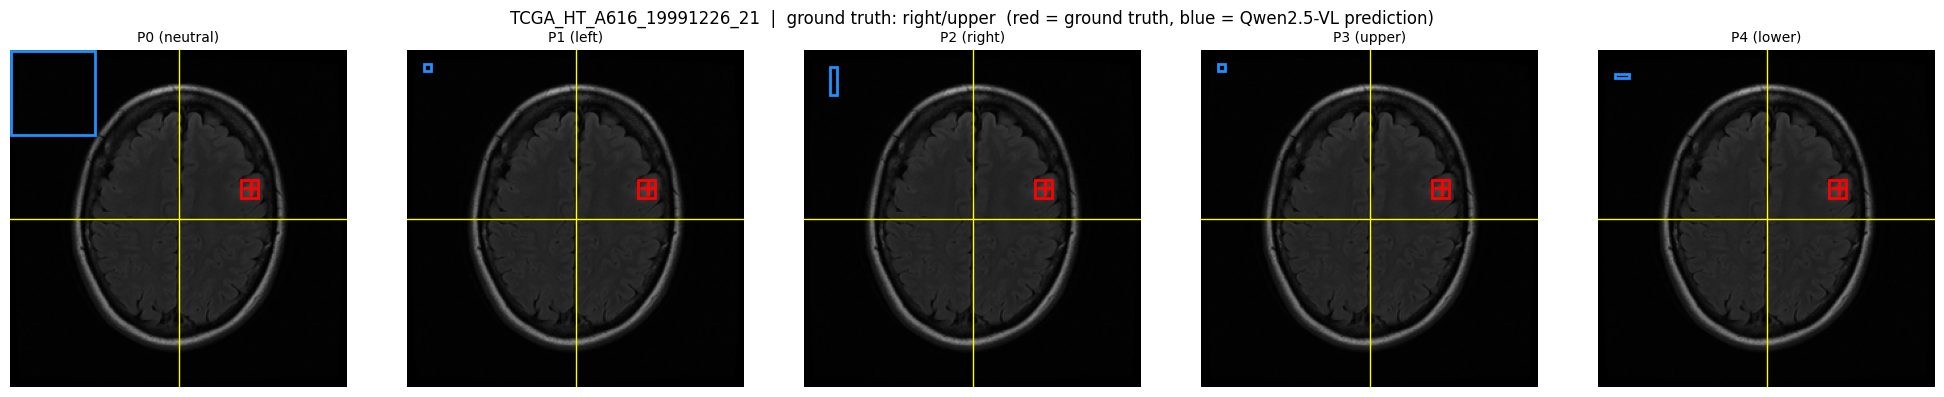

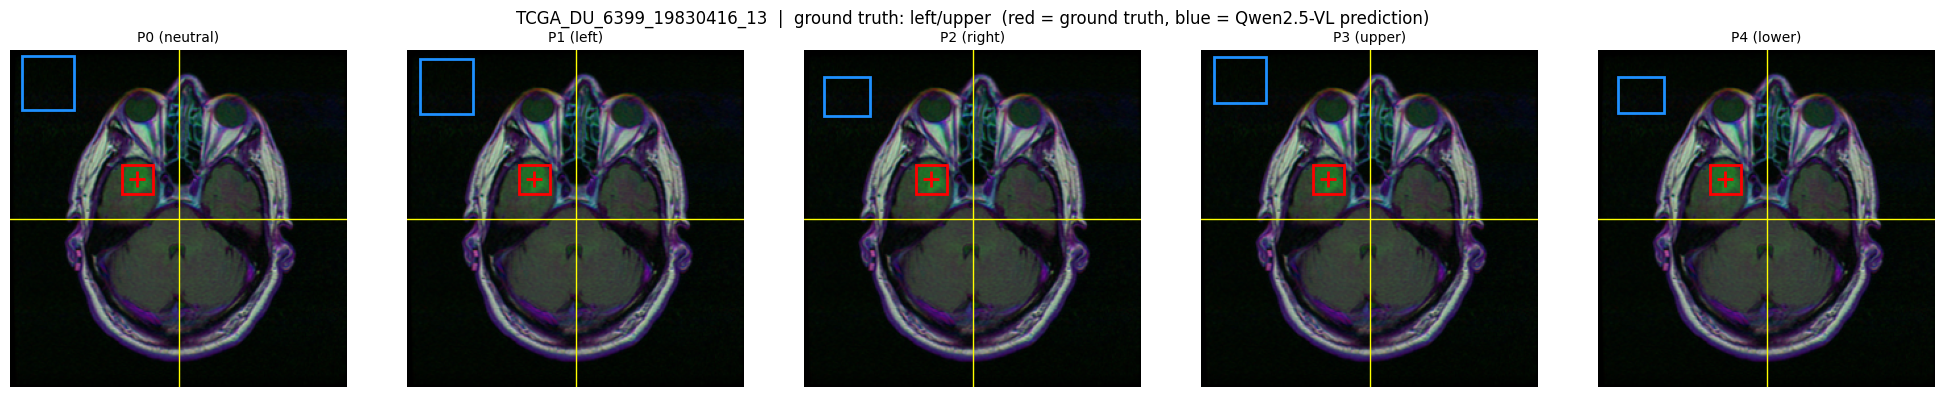

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_lgg_qwen25vl/visualizations
           qwen_correct_side  qwen_no_shift  qwen_iou  qwen_dist_norm
prompt_id                                                            
P1                      1.00       0.833333  0.000243        0.383238
P2                      0.02       0.880000  0.000000        0.396708
P3                      1.00       0.860000  0.000000        0.417146
P4                      0.00       0.860000  0.000000        0.393376


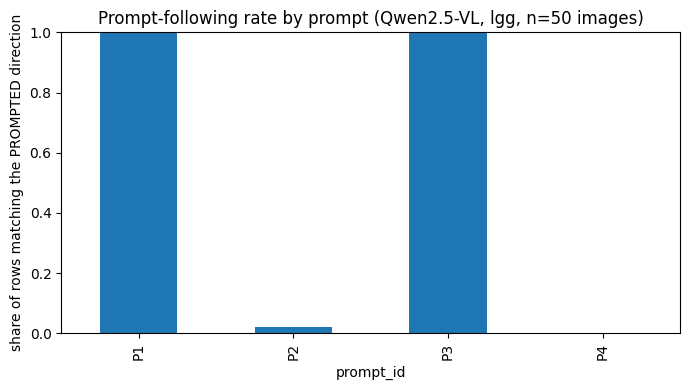

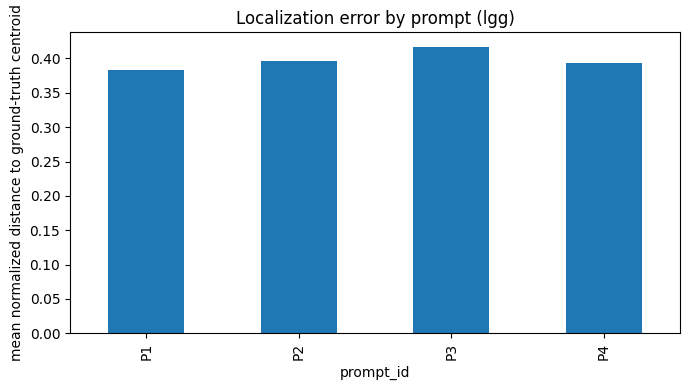

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_lgg_qwen25vl/lgg_qwen25vl_summary_by_prompt.csv
RQ2 (lgg) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           qwen_correct_side  qwen_dist_norm
prompt_id                                   
P1                  1.000000        0.320977
P2                  0.038462        0.453601
P3                  1.000000        0.385744
P4                  0.000000        0.450947

RQ3 (lgg) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           qwen_correct_side  qwen_dist_norm
prompt_id                                   
P1                       1.0        0.445499
P2                       0.0        0.335074
P3                       1.0        0.478103
P4                       0.0        0.363718

[ok] finished: ['kvasir', 'isic', 'lgg']


In [13]:
ALL_DATASETS = ["kvasir", "isic", "lgg"]

all_dfs = {}
for dataset_name in ALL_DATASETS:
    print(f"\n{'=' * 80}\nProcessing dataset: {dataset_name}\n{'=' * 80}")
    data_dir, out_dir, vis_dir = get_dataset_paths(dataset_name, f"results_{dataset_name}_qwen25vl")

    manifest_df = load_manifest(dataset_name, data_dir)
    result_df = run_qwen_inference(model, processor, DEVICE, manifest_df, data_dir, desc=f"Qwen2.5-VL inference ({dataset_name})")
    result_df = score_predictions(result_df, data_dir)
    save_results(result_df, out_dir, dataset_name)
    render_visualizations(result_df, data_dir, vis_dir, dataset_name, show_first=2)
    aggregate_and_report(result_df, out_dir, dataset_name)
    report_rq2_rq3(result_df, dataset_name)

    all_dfs[dataset_name] = result_df

print("\n[ok] finished:", list(all_dfs.keys()))